# Módulo 1: Dataset, Auditoría, EDA y Decisiones de Preparación
## Proyecto Final MLOps — Predicción de Precios de Vehículos de Ocasión (CarDekho)

### 1. Elección Justificada del Dataset (M1.1)
* **Ruta elegida:** Opción A — Dataset de la casa **Vehicle Dataset from CarDekho** ([Kaggle](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)), con su problema natural de **regresión supervisada** sobre `selling_price`.
* **Fichero utilizado:** `CAR DETAILS FROM CAR DEKHO.csv` (4.340 filas × 8 columnas).
* **Por qué este fichero:** Incluye únicamente atributos que cualquier persona conoce de su coche (marca/modelo, año, kilómetros, combustible, vendedor, transmisión, propietarios). Esto permite construir la mini-app de M4 para un usuario final real sin pedir datos técnicos complejos (cilindrada, par motor, potencia máxima).
* **Target:** `selling_price` (precio de reventa en rupias indias, INR; en la API/App se muestra convertido a EUR).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RAW_PATH = os.path.join("..", "data", "raw", "car_details.csv")
if not os.path.exists(RAW_PATH):
    RAW_PATH = os.path.join("data", "raw", "car_details.csv")

df = pd.read_csv(RAW_PATH)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### 2. Auditoría Inicial del Dataset (M1.2)
Impresión explícita de dimensiones, tipos de datos, valores nulos, duplicados y estadísticas del target.

In [2]:
print("=" * 55)
print("AUDITORÍA INICIAL DEL DATASET")
print("=" * 55)
print(f"Filas:    {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores nulos por columna:")
print(df.isnull().sum())
print(f"\nRegistros duplicados: {df.duplicated().sum()} ({df.duplicated().mean()*100:.2f}%)")
print("\nEstadísticas del Target (selling_price):")
print(df["selling_price"].describe().round(2))

AUDITORÍA INICIAL DEL DATASET
Filas:    4340
Columnas: 8

Tipos de datos:
name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
dtype: object

Valores nulos por columna:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Registros duplicados: 763 (17.58%)

Estadísticas del Target (selling_price):
count       4340.00
mean      504127.31
std       578548.74
min        20000.00
25%       208749.75
50%       350000.00
75%       600000.00
max      8900000.00
Name: selling_price, dtype: float64


**Conclusiones de la auditoría:**
- No hay valores nulos (0 en todas las columnas).
- Hay **763 filas exactamente duplicadas (17,58%)**, un problema serio de calidad que hay que limpiar antes de dividir en train/val/test.
- `selling_price` presenta una fuerte asimetría positiva (mediana 350.000 frente a un máximo de 8.900.000).

### 3. EDA Visual Completa (M1.3)
1. Univariante numérica (`selling_price`, `km_driven`)
2. Univariante categórica (`fuel`, `seller_type`, `transmission`, `owner`)
3. Bivariante contra el target
4. Detección de outliers
5. Correlaciones numéricas

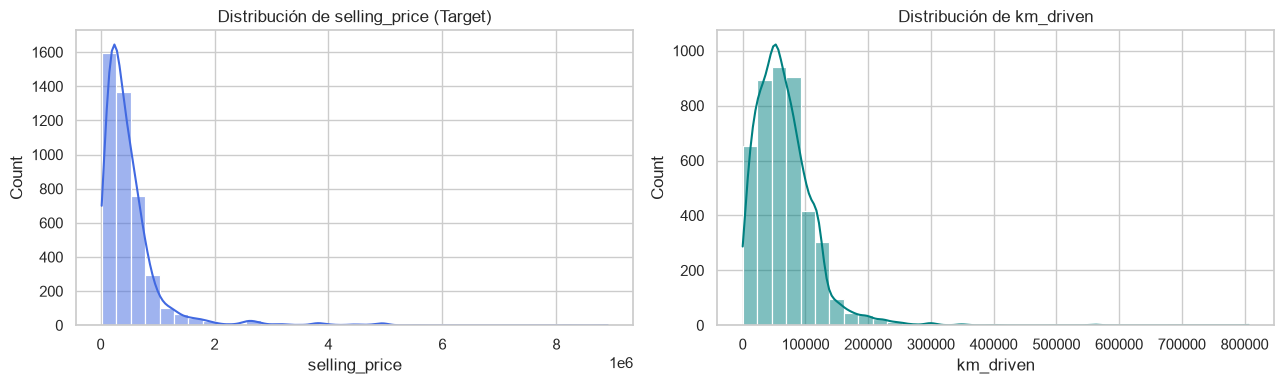

In [3]:
# 3.1 Univariante numérica
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["selling_price"], kde=True, ax=axes[0], color="royalblue", bins=35)
axes[0].set_title("Distribución de selling_price (Target)")
sns.histplot(df["km_driven"], kde=True, ax=axes[1], color="teal", bins=35)
axes[1].set_title("Distribución de km_driven")
plt.tight_layout()
plt.show()

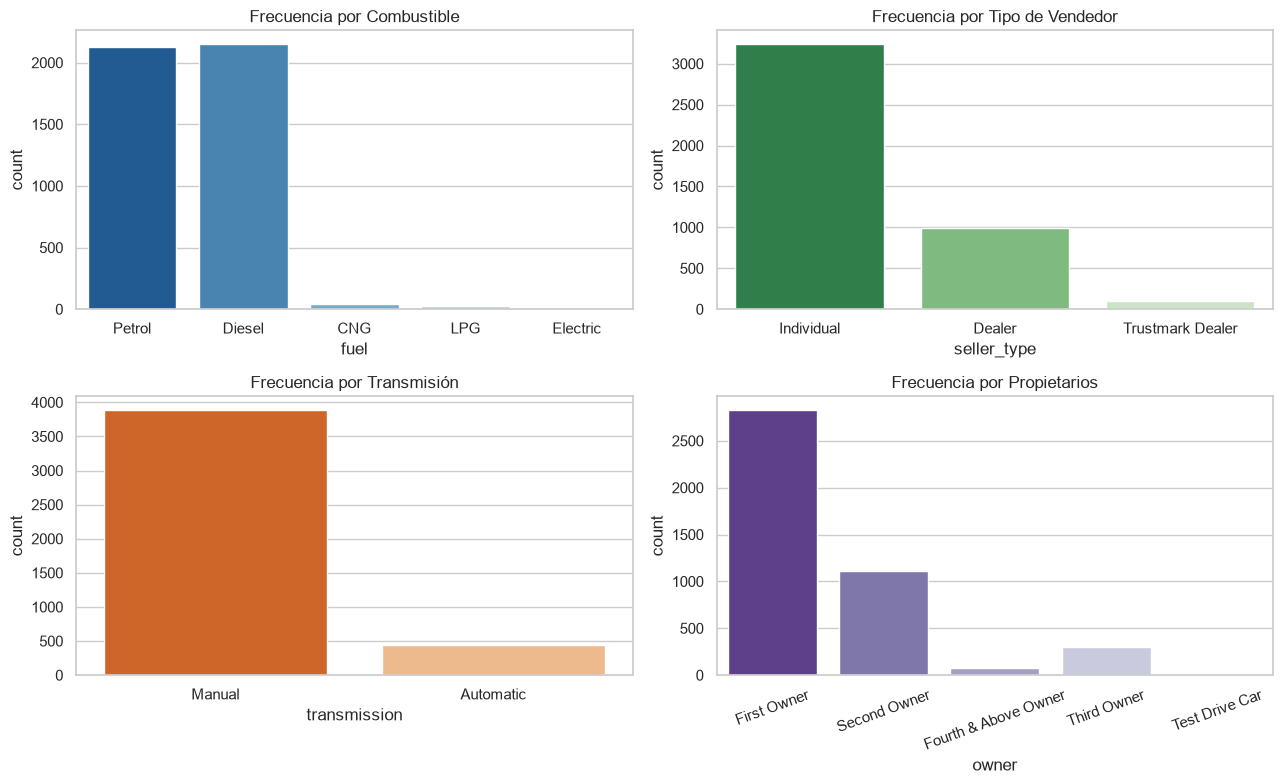

In [4]:
# 3.2 Univariante categórica
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.countplot(data=df, x="fuel", ax=axes[0, 0], palette="Blues_r", hue="fuel", legend=False)
axes[0, 0].set_title("Frecuencia por Combustible")
sns.countplot(data=df, x="seller_type", ax=axes[0, 1], palette="Greens_r", hue="seller_type", legend=False)
axes[0, 1].set_title("Frecuencia por Tipo de Vendedor")
sns.countplot(data=df, x="transmission", ax=axes[1, 0], palette="Oranges_r", hue="transmission", legend=False)
axes[1, 0].set_title("Frecuencia por Transmisión")
sns.countplot(data=df, x="owner", ax=axes[1, 1], palette="Purples_r", hue="owner", legend=False)
axes[1, 1].set_title("Frecuencia por Propietarios")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

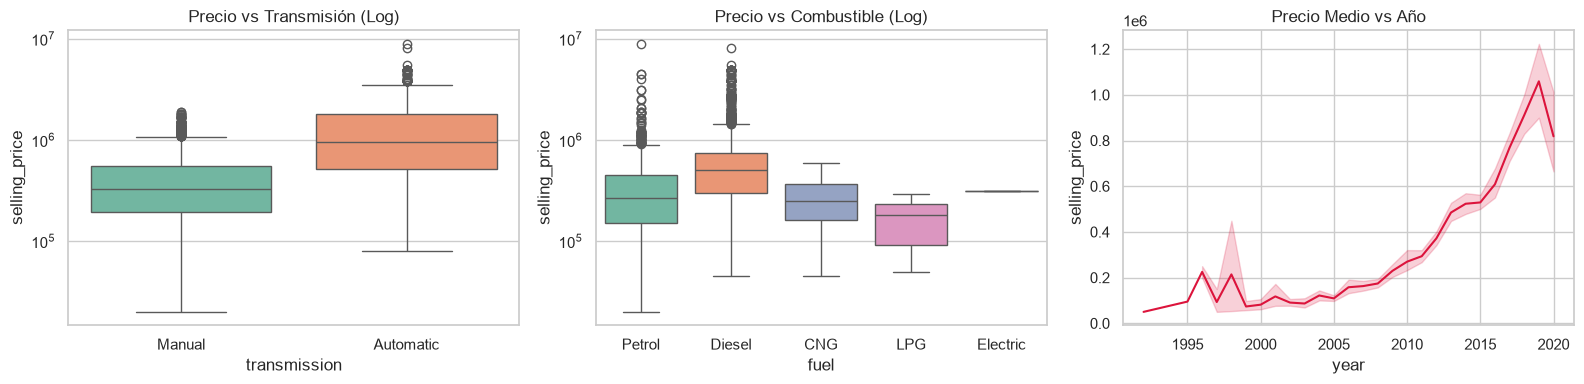

In [5]:
# 3.3 Bivariante contra el Target
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x="transmission", y="selling_price", ax=axes[0], palette="Set2", hue="transmission", legend=False)
axes[0].set_yscale("log")
axes[0].set_title("Precio vs Transmisión (Log)")

sns.boxplot(data=df, x="fuel", y="selling_price", ax=axes[1], palette="Set2", hue="fuel", legend=False)
axes[1].set_yscale("log")
axes[1].set_title("Precio vs Combustible (Log)")

sns.lineplot(data=df, x="year", y="selling_price", ax=axes[2], color="crimson")
axes[2].set_title("Precio Medio vs Año")
plt.tight_layout()
plt.show()

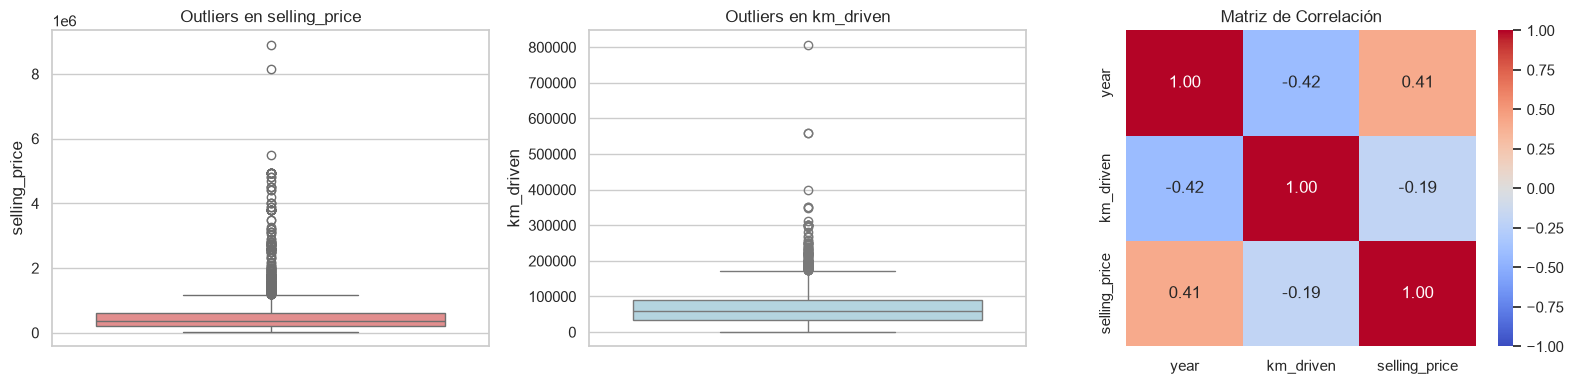

In [6]:
# 3.4 Outliers y 3.5 Correlaciones
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(y=df["selling_price"], ax=axes[0], color="lightcoral")
axes[0].set_title("Outliers en selling_price")
sns.boxplot(y=df["km_driven"], ax=axes[1], color="lightblue")
axes[1].set_title("Outliers en km_driven")
sns.heatmap(df[["year", "km_driven", "selling_price"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title("Matriz de Correlación")
plt.tight_layout()
plt.show()

### 4. Las 5 Decisiones de Preparación Justificadas (M1.4)
Cada decisión cuenta con su razonamiento escrito y su gráfica de apoyo.

#### Decisión 1 (Drop): Eliminación de 763 filas duplicadas
- **Razonamiento:** El 17,58% del dataset son copias exactas. Si se mantienen, un mismo anuncio puede caer en `train` y en `test` a la vez (fuga de datos / *data leakage*) e inflar artificialmente las métricas.

Filas antes: 4340 -> Filas después: 3577 (eliminados 763 duplicados)


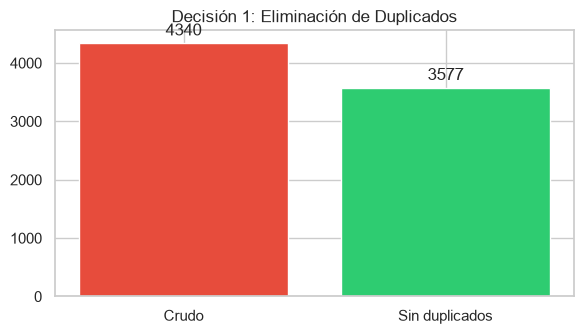

In [7]:
n_raw = len(df)
df1 = df.drop_duplicates().copy()
print(f"Filas antes: {n_raw} -> Filas después: {len(df1)} (eliminados {n_raw - len(df1)} duplicados)")

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["Crudo", "Sin duplicados"], [n_raw, len(df1)], color=["#e74c3c", "#2ecc71"])
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_title("Decisión 1: Eliminación de Duplicados")
plt.tight_layout()
plt.show()

#### Decisión 2 (Crear): Extraer `brand` y `car_model` desde `name`
- **Razonamiento:** La columna `name` tiene **1.491** cadenas únicas (ej. `Maruti Swift Dzire VDI`). Con tanta cardinalidad, el modelo memoriza nombres en vez de generalizar. Extrayendo la primera palabra (`brand`, 29 marcas) y la segunda (`car_model`, 183 modelos) conservamos la señal del fabricante y de la gama sin ruido de versiones menores.

De 1491 nombres únicos -> 29 marcas y 183 modelos


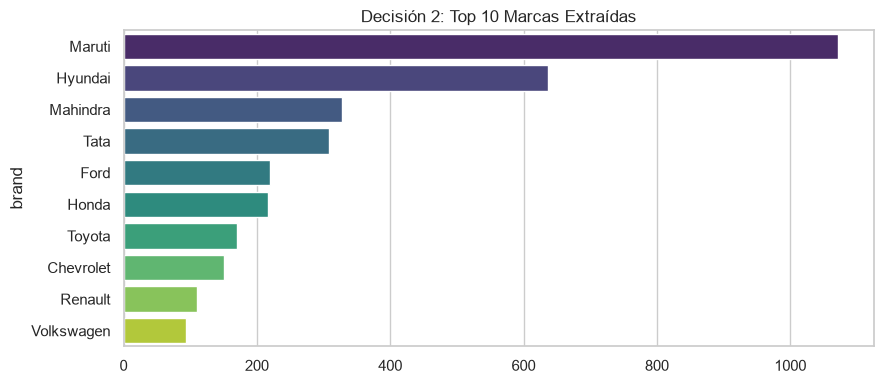

In [8]:
df2 = df1.copy()
df2["brand"] = df2["name"].apply(lambda x: str(x).split(" ")[0].strip().title())
df2["car_model"] = df2["name"].apply(lambda x: str(x).split(" ")[1].strip().title() if len(str(x).split(" ")) > 1 else "Unknown")
print(f"De {df['name'].nunique()} nombres únicos -> {df2['brand'].nunique()} marcas y {df2['car_model'].nunique()} modelos")

top_brands = df2["brand"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=top_brands.values, y=top_brands.index, palette="viridis", hue=top_brands.index, legend=False, ax=ax)
ax.set_title("Decisión 2: Top 10 Marcas Extraídas")
plt.tight_layout()
plt.show()

#### Decisión 3 (Crear / Transformar): Antigüedad del vehículo `vehicle_age`
- **Razonamiento:** Calculamos `vehicle_age = 2020 - year` (tomando 2020 como año del dataset). La antigüedad muestra directamente la curva de depreciación del vehículo. *(Nota: en el pipeline de producción usamos `year` directamente para que el usuario de la API introduzca el año que conoce, ya que `2020 - year` es una transformación lineal equivalente).*

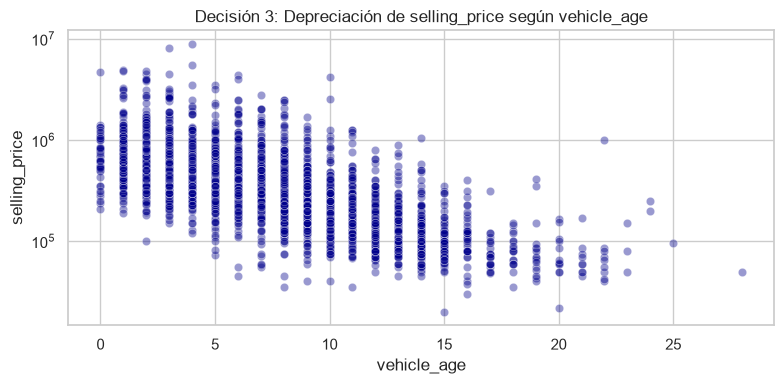

In [9]:
df3 = df2.copy()
df3["vehicle_age"] = 2020 - df3["year"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=df3, x="vehicle_age", y="selling_price", alpha=0.4, color="darkblue", ax=ax)
ax.set_yscale("log")
ax.set_title("Decisión 3: Depreciación de selling_price según vehicle_age")
plt.tight_layout()
plt.show()

#### Decisión 4 (Filtro / Drop): Acotar outliers extremos en `km_driven`
- **Razonamiento:** Hay coches con `1 km` (errores de carga) y extremos de más de `800.000 km`. Filtramos fuera del rango `[500 km, percentil 99.5 (~250.720 km)]` para evitar que estos puntos extremos distorsionen la escala y los modelos.

Percentil 99.5: 250,720 km | Eliminados: 22 registros | Restantes: 3555


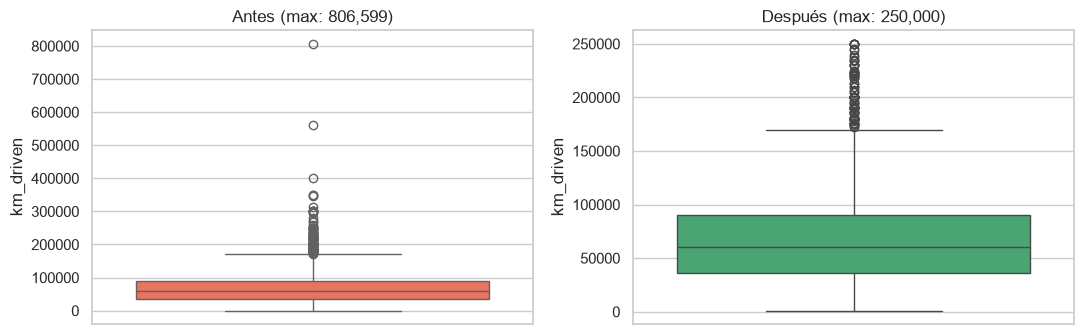

In [10]:
km_cap = df3["km_driven"].quantile(0.995)
df4 = df3[(df3["km_driven"] >= 500) & (df3["km_driven"] <= km_cap)].copy()
print(f"Percentil 99.5: {km_cap:,.0f} km | Eliminados: {len(df3) - len(df4)} registros | Restantes: {len(df4)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(y=df3["km_driven"], ax=axes[0], color="tomato")
axes[0].set_title(f"Antes (max: {df3['km_driven'].max():,.0f})")
sns.boxplot(y=df4["km_driven"], ax=axes[1], color="mediumseagreen")
axes[1].set_title(f"Después (max: {df4['km_driven'].max():,.0f})")
plt.tight_layout()
plt.show()

#### Decisión 5 (Recodificar): Escala ordinal de `owner` y binaria de `transmission`
- **Razonamiento:** `owner` tiene un orden natural de desgaste (`Test Drive Car = 0` hasta `Fourth & Above Owner = 4`), y `transmission` es binaria (`Manual = 0`, `Automatic = 1`). Al visualizarlas contra el precio se confirma que los automáticos y con menos dueños tienen precios claramente superiores.

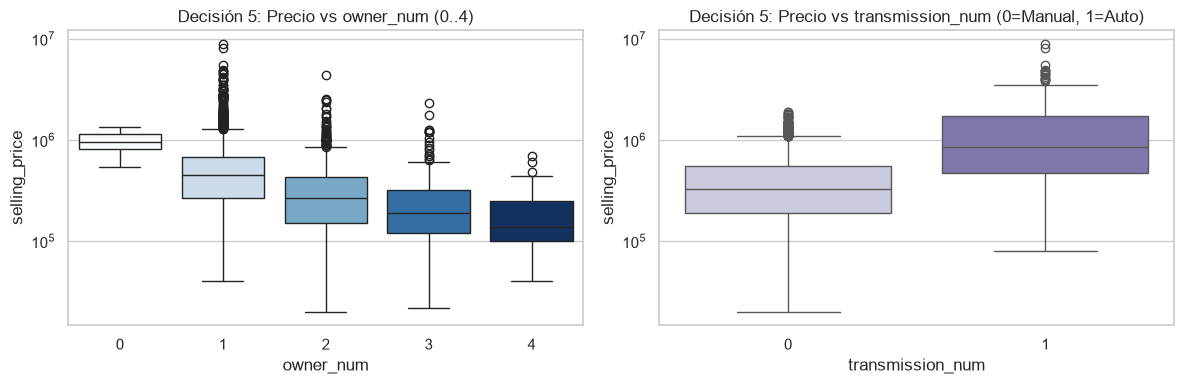

In [11]:
owner_map = {
    "Test Drive Car": 0,
    "First Owner": 1,
    "Second Owner": 2,
    "Third Owner": 3,
    "Fourth & Above Owner": 4,
}
df5 = df4.copy()
df5["owner_num"] = df5["owner"].map(owner_map).fillna(1).astype(int)
df5["transmission_num"] = (df5["transmission"] == "Automatic").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df5, x="owner_num", y="selling_price", ax=axes[0], palette="Blues", hue="owner_num", legend=False)
axes[0].set_yscale("log")
axes[0].set_title("Decisión 5: Precio vs owner_num (0..4)")
sns.boxplot(data=df5, x="transmission_num", y="selling_price", ax=axes[1], palette="Purples", hue="transmission_num", legend=False)
axes[1].set_yscale("log")
axes[1].set_title("Decisión 5: Precio vs transmission_num (0=Manual, 1=Auto)")
plt.tight_layout()
plt.show()